In [25]:
!pip install -q qiskit qiskit-aer matplotlib numpy tabulate

import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

simulator = AerSimulator()

In [26]:
def build_clean_interferometer(theta: float = np.pi / 2) -> QuantumCircuit:
    qc = QuantumCircuit(1, 1)
    qc.ry(theta, 0)
    qc.ry(-theta, 0)
    qc.measure(0, 0)
    return qc

qc_clean = build_clean_interferometer(theta=np.pi / 2)
counts_clean = simulator.run(transpile(qc_clean, simulator), shots=5000).result().get_counts()
print("Clean Interferometer Counts:", counts_clean)

Clean Interferometer Counts: {'0': 5000}


In [27]:
def build_bomb_tester(theta: float = np.pi / 2) -> QuantumCircuit:
    qc = QuantumCircuit(2, 2)
    qc.ry(theta, 0)
    qc.cx(0, 1)
    qc.ry(-theta, 0)
    qc.measure([0, 1], [0, 1])
    return qc

def evaluate_bomb_circuit(theta: float, shots: int = 30000, noise_model: NoiseModel = None):
    backend = AerSimulator(noise_model=noise_model) if noise_model else simulator
    qc = build_bomb_tester(theta=theta)
    counts = backend.run(transpile(qc, backend), shots=shots).result().get_counts()

    exp = sum(v for k, v in counts.items() if k[0] == '1')
    det = sum(v for k, v in counts.items() if k == '01')
    inc = sum(v for k, v in counts.items() if k == '00')

    p_exp = exp / shots
    p_det = det / shots
    p_inc = inc / shots
    score = p_det / p_exp if p_exp > 0 else 0.0

    return p_exp, p_det, p_inc, score

p_exp_std, p_det_std, p_inc_std, score_std = evaluate_bomb_circuit(theta=np.pi / 2, shots=30000)
p_exp_opt, p_det_opt, p_inc_opt, score_opt = evaluate_bomb_circuit(theta=np.pi / 3, shots=30000)

summary_table = [
    ["Standard (theta = pi/2)", f"{p_det_std*100:.2f}%", f"{p_exp_std*100:.2f}%", f"{p_inc_std*100:.2f}%", f"{score_std*100:.2f}%"],
    ["Improved (theta = pi/3)", f"{p_det_opt*100:.2f}%", f"{p_exp_opt*100:.2f}%", f"{p_inc_opt*100:.2f}%", f"{score_opt*100:.2f}%"]
]

print(tabulate(summary_table, headers=["Setup", "Detection (Safe)", "Explosion (Hit)", "Inconclusive", "IF Score"], tablefmt="github"))

| Setup                   | Detection (Safe)   | Explosion (Hit)   | Inconclusive   | IF Score   |
|-------------------------|--------------------|-------------------|----------------|------------|
| Standard (theta = pi/2) | 25.14%             | 49.78%            | 25.08%         | 50.51%     |
| Improved (theta = pi/3) | 18.70%             | 24.99%            | 56.31%         | 74.82%     |


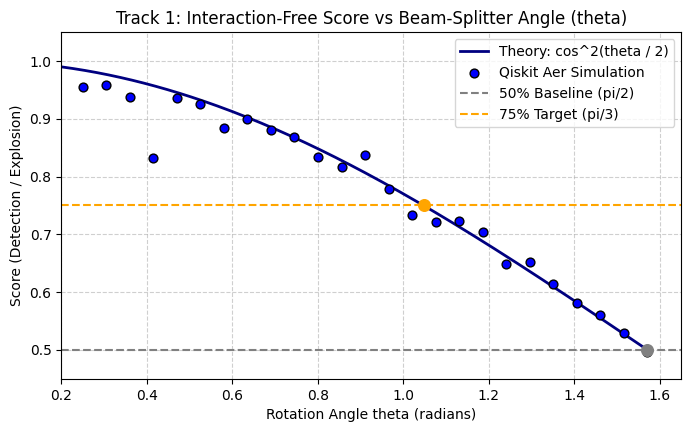

In [29]:
angles = np.linspace(0.25, np.pi / 2, 25)
simulated_scores = []

for th in angles:
    _, _, _, sc = evaluate_bomb_circuit(theta=th, shots=35000)
    simulated_scores.append(sc)

th_dense = np.linspace(0.20, np.pi / 2, 200)
analytical_scores = np.cos(th_dense / 2) ** 2

plt.figure(figsize=(8, 4.5))
plt.plot(th_dense, analytical_scores, color='navy', linestyle='-', lw=2, label='Theory: cos^2(theta / 2)')
plt.scatter(angles, simulated_scores, color='blue', edgecolors='black', s=40, zorder=4, label='Qiskit Aer Simulation')
plt.axhline(y=0.50, color='gray', linestyle='--', label='50% Baseline (pi/2)')
plt.axhline(y=0.75, color='orange', linestyle='--', label='75% Target (pi/3)')
plt.scatter([np.pi/2], [0.50], color='gray', s=70, zorder=5)
plt.scatter([np.pi/3], [0.75], color='orange', s=70, zorder=5)
plt.title("Track 1: Interaction-Free Score vs Beam-Splitter Angle (theta)")
plt.xlabel("Rotation Angle theta (radians)")
plt.ylabel("Score (Detection / Explosion)")
plt.ylim(0.45, 1.05)
plt.xlim(0.20, 1.65)
plt.legend(loc='upper right')
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

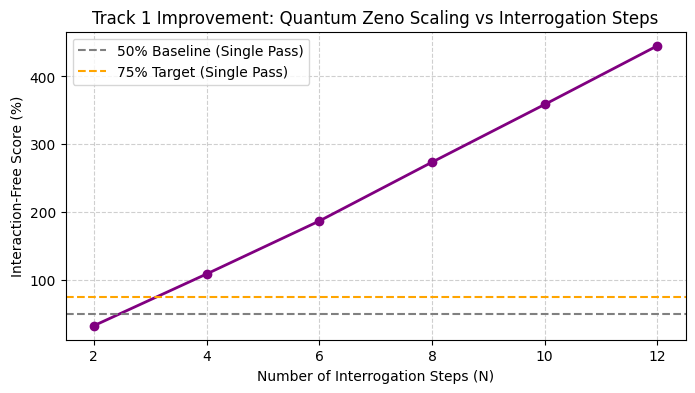

In [30]:
def run_quantum_zeno_tester(steps: int = 8, shots: int = 20000):
    qc = QuantumCircuit(1 + steps, 1 + steps)
    theta = np.pi / steps

    for i in range(steps):
        qc.ry(theta, 0)
        qc.cx(0, i + 1)
        qc.measure(i + 1, i + 1)

    qc.measure(0, 0)
    counts = simulator.run(transpile(qc, simulator), shots=shots).result().get_counts()

    exploded = sum(v for k, v in counts.items() if any(bit == '1' for bit in k[:-1]))
    detected = sum(v for k, v in counts.items() if k[-1] == '0' and all(bit == '0' for bit in k[:-1]))

    p_exp = exploded / shots
    p_det = detected / shots
    score = p_det / p_exp if p_exp > 0 else 0.0
    return p_det, p_exp, score

zeno_steps = [2, 4, 6, 8, 10, 12]
zeno_scores = []

for s in zeno_steps:
    _, _, z_sc = run_quantum_zeno_tester(steps=s, shots=20000)
    zeno_scores.append(z_sc)

plt.figure(figsize=(8, 4))
plt.plot(zeno_steps, [sc * 100 for sc in zeno_scores], marker='o', color='purple', lw=2)
plt.axhline(y=50, color='gray', linestyle='--', label='50% Baseline (Single Pass)')
plt.axhline(y=75, color='orange', linestyle='--', label='75% Target (Single Pass)')
plt.title("Track 1 Improvement: Quantum Zeno Scaling vs Interrogation Steps")
plt.xlabel("Number of Interrogation Steps (N)")
plt.ylabel("Interaction-Free Score (%)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

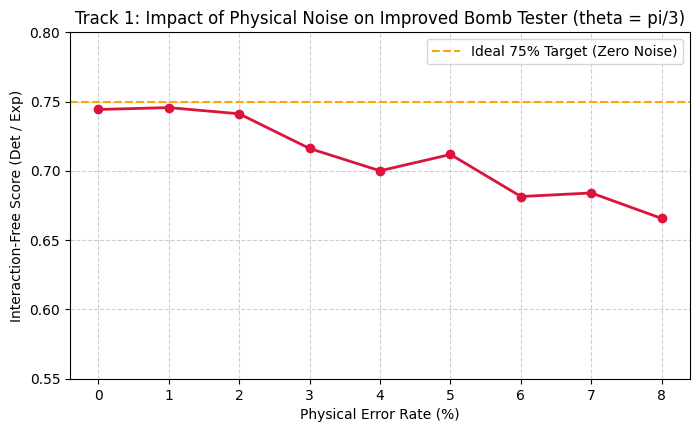

In [31]:
noise_levels = np.linspace(0.0, 0.08, 9)
noisy_scores = []

for p in noise_levels:
    nm = None
    if p > 0:
        nm = NoiseModel()
        nm.add_all_qubit_quantum_error(depolarizing_error(p, 1), ['ry'])
        nm.add_all_qubit_quantum_error(depolarizing_error(p * 2, 2), ['cx'])
        nm.add_all_qubit_readout_error(ReadoutError([[1 - p, p], [p, 1 - p]]))

    _, _, _, sc = evaluate_bomb_circuit(theta=np.pi / 3, shots=40000, noise_model=nm)
    noisy_scores.append(sc)

plt.figure(figsize=(8, 4.5))
plt.plot(noise_levels * 100, noisy_scores, marker='o', color='crimson', lw=2)
plt.axhline(y=0.75, color='orange', linestyle='--', label='Ideal 75% Target (Zero Noise)')
plt.title("Track 1: Impact of Physical Noise on Improved Bomb Tester (theta = pi/3)")
plt.xlabel("Physical Error Rate (%)")
plt.ylabel("Interaction-Free Score (Det / Exp)")
plt.ylim(0.55, 0.80)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()